# Resolution GUI example

Place USAF 1951 line profiles in a **popup window**, then this notebook
measures contrast on the original image. Plots stay **inside the notebook**.

**How to run**

1. Run the cells from top to bottom.
2. In *Choose your image*, either keep the example image or uncomment `IMAGE_PATH`.
3. In *Analysis options*, leave one `MODE` uncommented.
4. When the selection window opens, place both points, drag a **+** to
   adjust if needed, then press **Enter** or close the window. That is the
   same confirm path as the ``resolution_gui_example.py`` script.
5. If a cell says nothing was selected yet, confirm in the window, then
   rerun that cell. Restart the kernel after updating QAL so the picker
   loads the latest code.


## 1. Setup


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from qal import RrtAnalyzer, RrtDataPlotter, RrtLineSelection, RrtROI, select_rrt_lines
from qal.data import res_sample_1
from qal.util import load_grayscale_image

from qal.util import save_sample_sources


## 2. Choose your image

`IMAGE_PATH = res_sample_1()` loads the built-in example image.

To use your own image, comment out that line and set `IMAGE_PATH` to a
TIFF, BMP, PNG, or JPEG file path. Leave only one option active.
The relative file path works from this notebook's folder in a GitHub checkout or download.

`None` raises an error because no image has been supplied.

**Quantitative image input:** this example passes the input through
`load_grayscale_image` before analysis. Native 2-D grayscale values are
preserved without rescaling. RGB inputs use scikit-image's `rgb2gray`
luminance weighting of all three channels and return floating-point values.
See [image input handling](../../../doc/image_inputs.md) for details.


In [2]:
# Images are loaded and converted to grayscale with load_grayscale_image.
# Already-grayscale images remain unchanged: stored values and dtype are preserved.
# RGB uses scikit-image rgb2gray weights across all channels (floating-point output).
# Choose one option; leave the others commented out.
# Uncomment the next line and put the path to your image:
# IMAGE_PATH = "/path/to/your/image.tiff"

# Example using a file that ships with QAL:
# Run from this example's directory in a GitHub checkout or download.
# IMAGE_PATH = "../../data/resolution_targets/res_sample_1.tiff"

# Selecting the built-in example image:
IMAGE_PATH = res_sample_1()


  0%|                                              | 0.00/2.51M [00:00<?, ?B/s]

## 3. Analysis options

When `SAVE_RESULTS` is `True`:

- If you set `IMAGE_PATH` to a file path, files go next to that image in `<image_name>_results/`
- If you use the built-in image, files go next to this notebook in `res_sample_1_results/`

Pick one mode. `automatic_refinement` snaps two clicks onto the chart.
`manual_live_preview` drags two crosshairs and updates the profiles as you drag.
`manual_line_profiles` draws each measurement line. `manual_coordinates`
skips the window and uses the coordinates below.

Set `SAVE_SOURCE_IMAGES = True` to also copy the original built-in sample
files. User-supplied images are not copied. Multiple source images are grouped
in `source_images/`. This does not move or change cached data.


In [ ]:
SAVE_RESULTS = True
# Optional: copy original built-in samples; user-supplied images are not copied.
SAVE_SOURCE_IMAGES = True

# MODE = "automatic_refinement"
MODE = "manual_live_preview"
# MODE = "manual_line_profiles"
# MODE = "manual_coordinates"

# True shows a straightened crop. Contrast is still measured on the original image.
AUTO_CROP = True

# Used only by manual_line_profiles. How many lines to draw, from 1 to 6.
LINE_COUNT = 3

# Leave both as None to choose the points in the window.
REGISTRATION_POINTS = None
# REGISTRATION_POINTS = [(54.9, 76.6), (202.8, 215.4)]

LINE_COORDINATES = None
# LINE_COORDINATES = [
#     ((63.5, 71.7), (63.5, 220.0)),
#     ((198.7, 74.2), (198.7, 169.3)),
#     ((131.4, 125.2), (131.4, 164.0)),
# ]

RESOLUTION_THRESHOLD = 26


## 4. Load the image


Results folder: /Users/eammon/Documents/GitHub/quel-qal/qal/examples/jupyter-notebook/res_sample_1_results


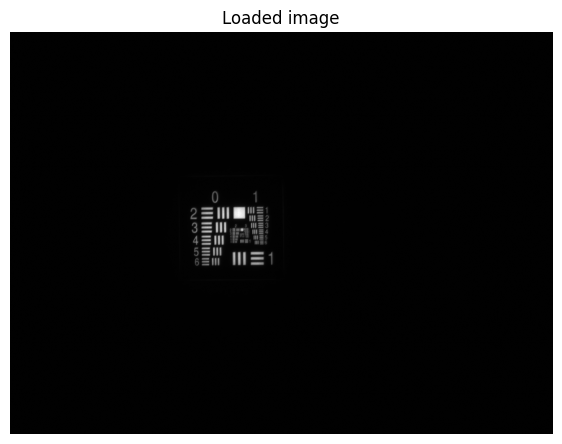

In [4]:
if IMAGE_PATH is None:
    raise ValueError("No image has been supplied. Set IMAGE_PATH to an image file path or a built-in example call.")

if isinstance(IMAGE_PATH, np.ndarray):
    image = load_grayscale_image(IMAGE_PATH)
    results_dir = Path("res_sample_1_results")
else:
    image = load_grayscale_image(IMAGE_PATH)
    image_file = Path(IMAGE_PATH).expanduser()
    results_dir = image_file.parent / f"{image_file.stem}_results"

if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)
    selection_path = results_dir / "selection.yaml"
    print(f"Results folder: {results_dir.resolve()}")
else:
    results_dir = None
    selection_path = None

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(image, cmap="gray")
ax.set_title("Loaded image")
ax.axis("off")
plt.show()


## 5. Crop the resolution chart

The crop is only for clicking. Contrast is measured on the original image.


  0%|                                               | 0.00/103k [00:00<?, ?B/s]

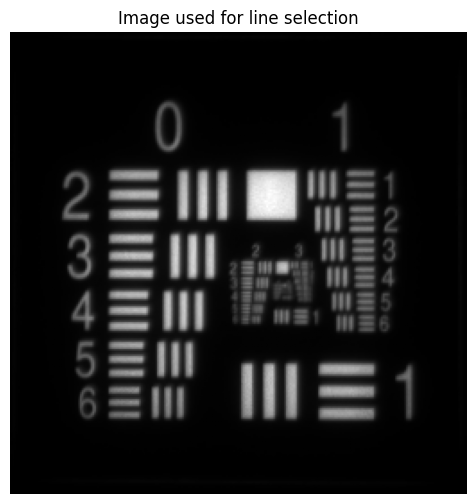

In [5]:
crop = None
if AUTO_CROP:
    crop = RrtROI().crop_resolution_target(image)
if AUTO_CROP and crop is None:
    raise RuntimeError("Could not find the resolution chart. Set AUTO_CROP = False.")

gui_image = crop.image if crop is not None else image

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(gui_image, cmap="gray")
ax.set_title("Image used for line selection")
ax.axis("off")
plt.show()


## 6. Place the lines (popup window)

Registration modes use two points:

1. Top-left of the top bar of Group 0, Element 2
2. Bottom-right of the bottom bar of Group 0, Element 1

After both points are placed, drag a **+** to adjust them. **Enter** or
the window close button accepts the selection, matching the script. If
this cell returns without a selection, confirm in the window, then rerun
the next cell.


In [6]:
selection = select_rrt_lines(
    gui_image,
    crop=crop,
    mode=MODE,
    line_count=LINE_COUNT,
    registration_points=REGISTRATION_POINTS,
    line_coordinates=LINE_COORDINATES,
    selection_path=selection_path,
)


Mode: manual_live_preview
1 → top-left corner of the top bar, Group 0 Element 2
2 → bottom-right corner of the bottom bar, Group 0 Element 1
Drag a +: move  |  lines and profiles update live
Right-click a +: clear it  |  Delete: undo last  |  Enter: confirm  |  Close the window: confirm
Opening a native Matplotlib window.

Selected coordinates:
REGISTRATION_POINTS = [(55.6, 77.1), (203.1, 217.7)]
LINE_COORDINATES = [
    ((64.1, 72.2), (64.1, 222.3)),
    ((199.0, 74.7), (199.0, 171.0)),
    ((131.9, 126.3), (131.9, 165.6)),
]
Saved selection to res_sample_1_results/selection.yaml


## 7. Measure contrast


In [7]:
chosen = selection if isinstance(selection, RrtLineSelection) else getattr(selection, "result", None)
if not isinstance(chosen, RrtLineSelection):
    raise RuntimeError(
        "No lines yet. Click Confirm in the selection window, then rerun this cell."
    )

if crop is not None:
    chosen = crop.selection_to_source(chosen)
    print("Lines on the original image:")
    print(chosen.describe())

group_coordinates = chosen.group_coordinates
percentage_contrast_df = RrtAnalyzer().load_and_process_groups(image, group_coordinates)
RrtROI.print_smallest_resolved(percentage_contrast_df, RESOLUTION_THRESHOLD)
percentage_contrast_df.drop(columns=["Peak Indices", "Trough Indices"])


Lines on the original image:
REGISTRATION_POINTS = [(458.0, 422.0), (607.2, 560.7)]
LINE_COORDINATES = [
    ((466.6, 417.0), (468.4, 567.4)),
    ((601.6, 418.0), (602.6, 514.2)),
    ((535.1, 470.4), (535.6, 509.7)),
]

Smallest feature above 26% contrast: Group 1, Element 5, 3.17 lp/mm


,Group,Element,Resolution (lp/mm),Line Width (microns),Percentage Contrast,Percentage Contrast Std
0,0,2,1.122462,445.45,79.975975,3.652727
1,0,3,1.259921,396.85,77.823067,4.358755
2,0,4,1.414214,353.55,74.159637,5.592113
3,0,5,1.587401,314.98,69.901955,6.164640
4,0,6,1.781797,280.62,59.972668,0.740665
5,1,1,2.000000,250.00,59.672451,8.930318
6,1,2,2.244924,222.72,52.410278,10.501953
7,1,3,2.519842,198.43,45.792561,9.553552
8,1,4,2.828427,176.78,35.563900,10.178340
9,1,5,3.174802,157.49,30.572815,9.251589


## 8. Plot line profiles


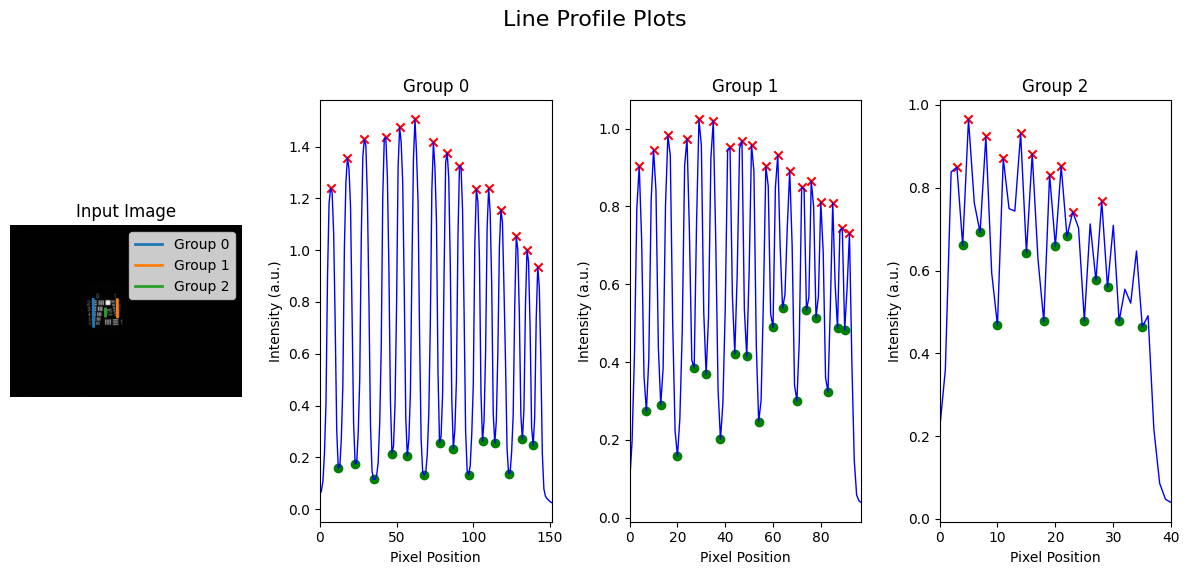

Saved res_sample_1_results/line_profiles.png


In [8]:
plotter = RrtDataPlotter()
line_profile_path = None if results_dir is None else results_dir / "line_profiles.png"
plotter.plot_line_profiles(
    image, group_coordinates, percentage_contrast_df, save_path=line_profile_path
)
if line_profile_path is not None:
    print(f"Saved {line_profile_path}")


## 9. Plot contrast vs resolution


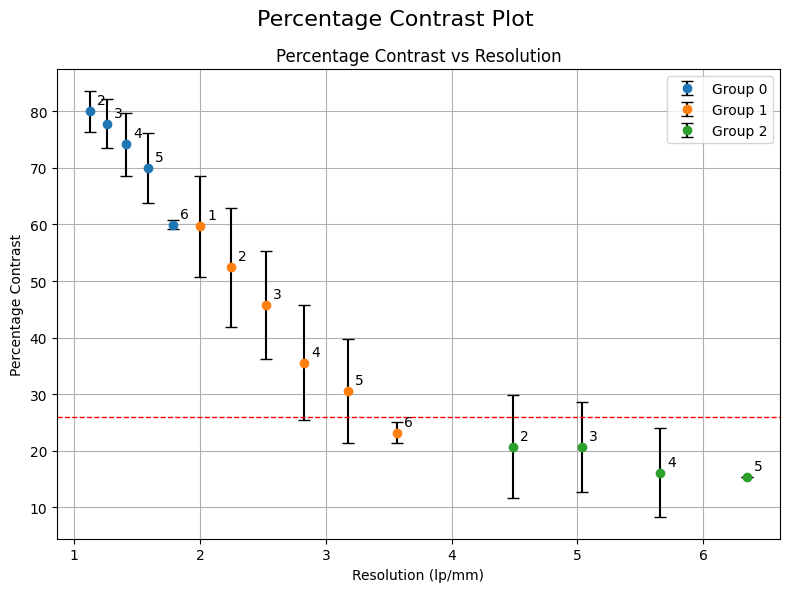

Saved res_sample_1_results/percentage_contrast.png


In [9]:
contrast_plot_path = None if results_dir is None else results_dir / "percentage_contrast.png"
plotter.plot_percentage_contrast(
    percentage_contrast_df,
    resolution_threshold=RESOLUTION_THRESHOLD,
    save_path=contrast_plot_path,
)
if contrast_plot_path is not None:
    print(f"Saved {contrast_plot_path}")


## 10. Save the contrast table as CSV


In [10]:
if results_dir is None:
    print("SAVE_RESULTS is False, so no CSV file was written.")
else:
    contrast_csv_path = results_dir / "percentage_contrast.csv"
    percentage_contrast_df.to_csv(contrast_csv_path, index=False)
    print(f"Saved {contrast_csv_path}")

    plotter.save_roi_image(image, group_coordinates, results_dir / "roi.png")
    if SAVE_SOURCE_IMAGES:
        save_sample_sources(results_dir, IMAGE_PATH)


Saved res_sample_1_results/percentage_contrast.csv
